# Week 1 Task 2 — Trends and the spaghetti problem

This notebook follows the Week 1 assignment brief and keeps each task in a separate file.

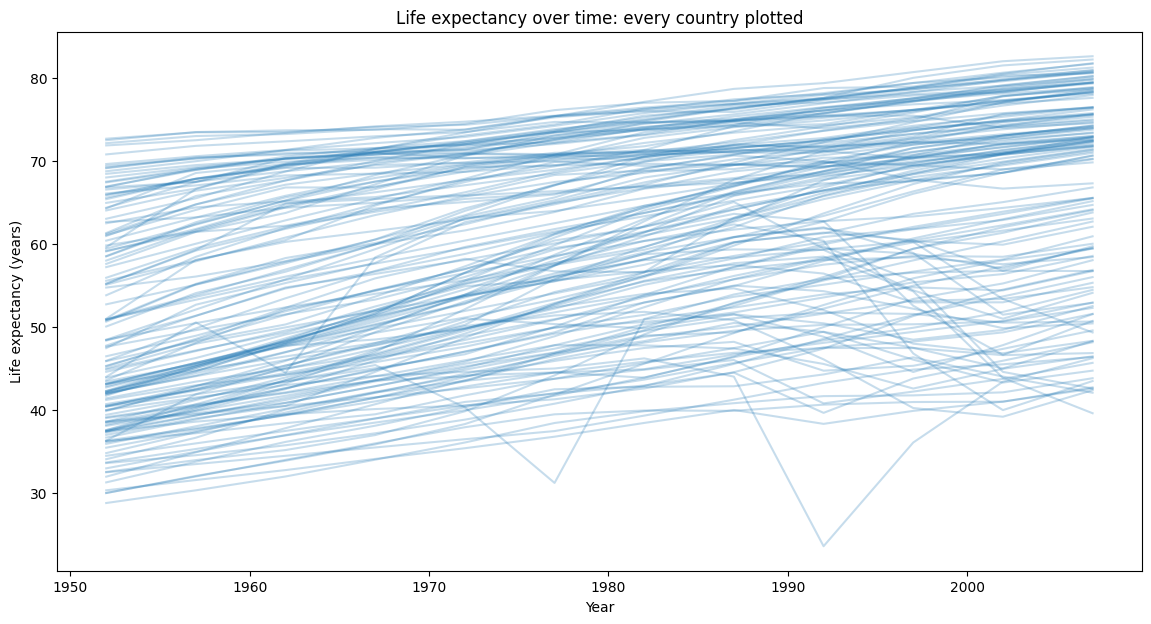

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week1/assignments/data/gapminder.csv')
if not path.exists():
    path = Path('assignments/data/gapminder.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week1/assignments/data/gapminder.csv')

df = pd.read_csv(path)
fig, ax = plt.subplots(figsize=(14, 7))
for country, group in df.groupby('country'):
    ax.plot(group['year'], group['lifeExp'], alpha=0.25, color='tab:blue')
ax.set_title('Life expectancy over time: every country plotted')
ax.set_xlabel('Year')
ax.set_ylabel('Life expectancy (years)')
plt.show()

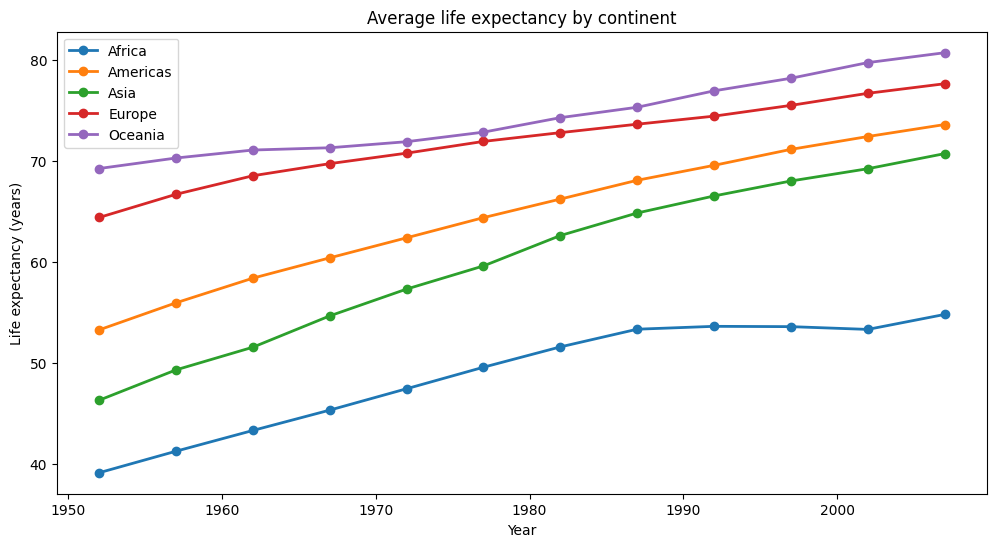

In [2]:
continent = df.groupby(['continent', 'year'], as_index=False)['lifeExp'].mean()
fig, ax = plt.subplots(figsize=(12, 6))
for name, g in continent.groupby('continent'):
    ax.plot(g['year'], g['lifeExp'], marker='o', linewidth=2, label=name)
ax.set_title('Average life expectancy by continent')
ax.set_xlabel('Year')
ax.set_ylabel('Life expectancy (years)')
ax.legend()
plt.show()

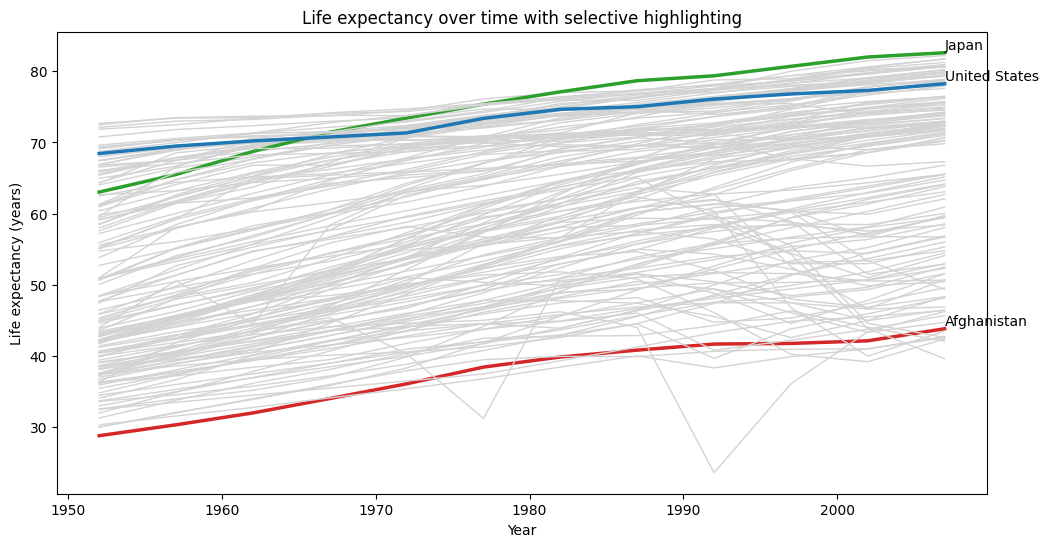

In [3]:
interesting = ['Afghanistan', 'Japan', 'United States']
fig, ax = plt.subplots(figsize=(12, 6))
for country, group in df.groupby('country'):
    if country in interesting:
        color = {'Afghanistan': '#d62728', 'Japan': '#2ca02c', 'United States': '#1f77b4'}[country]
        ax.plot(group['year'], group['lifeExp'], color=color, linewidth=2.5, label=country)
        ax.text(group['year'].iloc[-1], group['lifeExp'].iloc[-1], country, va='bottom', ha='left')
    else:
        ax.plot(group['year'], group['lifeExp'], color='lightgray', linewidth=1)
ax.set_title('Life expectancy over time with selective highlighting')
ax.set_xlabel('Year')
ax.set_ylabel('Life expectancy (years)')
ax.legend().remove()
plt.show()

In [ ]:
# The spaghetti plot is too crowded to read, while the grouped chart makes the broad trend clear. Highlighting a few countries keeps the country-level story while removing the visual noise.